In [1]:
from pathlib import Path
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

PROJECT = Path(
    r"C:\Users\XiXi\OneDrive\Documents\Stanford\CS230\pathmnist_project"
)
REPO = PROJECT / "cs230-pathmnist"
DATA = PROJECT / "data"
CHECKPOINTS = PROJECT / "checkpoints"
RESULTS = REPO / "results"

# Allow imports even if the notebook starts from another working folder.
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from src.data import load_split, CLASS_NAMES
from src.engine import run_experiment
from src.report import (
    load_results, results_table, plot_history,
    plot_confusion, per_class_table,
)

assert (DATA / "pathmnist_128.npz").exists(), \
    "Cannot find pathmnist_128.npz"

CHECKPOINTS.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "Unavailable")

COMMON = dict(
    data_size=128,
    batch_size=128,
    seed=0,
    num_workers=0,
    data_root=str(DATA),
    ckpt_dir=str(CHECKPOINTS),
    results_dir=str(RESULTS),
)

GPU: NVIDIA GeForce RTX 5090


## 1. Look at the training data
Class balance matters for interpreting accuracy vs. macro-F1: macro-F1 weights every class equally, accuracy weights every image equally.

In [8]:
x, y = load_split(str(DATA), 128, "train")
print("train images:", x.shape, x.dtype)

counts = np.bincount(y, minlength=len(CLASS_NAMES))
for name, c in zip(CLASS_NAMES, counts):
    print(f"{name:40s} {c:6d}  ({c / len(y):.1%})")

train images: (89996, 128, 128, 3) uint8
adipose                                    9366  (10.4%)
background                                 9509  (10.6%)
debris                                    10360  (11.5%)
lymphocytes                               10401  (11.6%)
mucus                                      8006  (8.9%)
smooth muscle                             12182  (13.5%)
normal colon mucosa                        7886  (8.8%)
cancer-associated stroma                   9401  (10.4%)
colorectal adenocarcinoma epithelium      12885  (14.3%)


## 2. Smoke test
Train on 10 batches per epoch for two epochs, and validates on only 10 batches. The purpose is to confirm that loading, GPU training, validation, and saving work. These scores are not full-dataset benchmark results.

In [2]:
smoke = run_experiment(
    name="baseline_cnn_128_smoke",
    model="baseline_cnn",
    epochs=2,
    limit_batches=10,
    lr=1e-3,
    save=True,
    **COMMON,
)

print("\nSmoke test completed")
print("Validation accuracy:", smoke["best_val"]["accuracy"])
print("Validation macro-F1:", smoke["best_val"]["macro_f1"])

Extracting C:\Users\XiXi\OneDrive\Documents\Stanford\CS230\pathmnist_project\data\pathmnist_128.npz -> C:\Users\XiXi\OneDrive\Documents\Stanford\CS230\pathmnist_project\data\pathmnist_128 (one time) ...
=== baseline_cnn_128_smoke: baseline_cnn, data 128x128, network input 128x128, 0.39M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 1.424 acc 0.487 F1 0.467 | val loss 2.130 acc 0.255 F1 0.137 | 16s  *best
ep 02 | lr 1.0e-03 | train loss 1.061 acc 0.626 F1 0.610 | val loss 1.832 acc 0.339 F1 0.216 | 0s  *best
Best epoch 2: val acc 0.3395, val macro-F1 0.2160, 8s/epoch train, 25671 img/s inference. Saved: C:\Users\XiXi\OneDrive\Documents\Stanford\CS230\pathmnist_project\results\baseline_cnn_128_smoke.json


Smoke test completed
Validation accuracy: 0.339453125
Validation macro-F1: 0.21599013308648737


# 3. The four runs
### 3.1 Baseline CNN on the full 128×128 training set
Train the baseline CNN on the full 128×128 training set

In [9]:
baseline = run_experiment(
    name="baseline_cnn_128_seed0",
    model="baseline_cnn",
    epochs=30,
    lr=1e-3,
    save=True,
    **COMMON,
)

print("\nFull baseline completed")
print("Best epoch:", baseline["best_epoch"])
print("Validation accuracy:", baseline["best_val"]["accuracy"])
print("Validation macro-F1:", baseline["best_val"]["macro_f1"])

=== baseline_cnn_128_seed0: baseline_cnn, data 128x128, network input 128x128, 0.39M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 0.357 acc 0.881 F1 0.879 | val loss 0.371 acc 0.865 F1 0.871 | 11s  *best
ep 02 | lr 1.0e-03 | train loss 0.149 acc 0.952 F1 0.951 | val loss 0.145 acc 0.954 F1 0.954 | 9s  *best
ep 03 | lr 1.0e-03 | train loss 0.112 acc 0.964 F1 0.963 | val loss 0.141 acc 0.955 F1 0.954 | 9s  *best
ep 04 | lr 1.0e-03 | train loss 0.093 acc 0.969 F1 0.969 | val loss 0.090 acc 0.971 F1 0.971 | 9s  *best
ep 05 | lr 1.0e-03 | train loss 0.081 acc 0.974 F1 0.974 | val loss 0.114 acc 0.967 F1 0.967 | 9s
ep 06 | lr 1.0e-03 | train loss 0.074 acc 0.976 F1 0.976 | val loss 0.149 acc 0.947 F1 0.947 | 9s
ep 07 | lr 1.0e-03 | train loss 0.065 acc 0.979 F1 0.979 | val loss 0.095 acc 0.971 F1 0.970 | 9s
ep 08 | lr 3.0e-04 | train loss 0.039 acc 0.988 F1 0.987 | val loss 0.031 acc 0.992 F1 0.992 | 9s  *best
ep 09 | lr 3.0e-04 | train loss 0.035 acc 0.989 F1 0.989 | val loss 0.0

### 3.2 ResNet-18 on the full 128×128 training set
Train ResNet-18 for 128×128 resolution data set. Keep the same data split, augmentation, batch size, and seed so we can compare it with the baseline.

In [11]:
resnet_scratch = run_experiment(
    name="resnet18_scratch_128_seed0",
    model="resnet18_scratch",
    epochs=30,
    lr=1e-3,
    save=True,
    **COMMON,
)

print("\nResNet-18 from scratch completed")
print("Best epoch:", resnet_scratch["best_epoch"])
print("Validation accuracy:", resnet_scratch["best_val"]["accuracy"])
print("Validation macro-F1:", resnet_scratch["best_val"]["macro_f1"])

=== resnet18_scratch_128_seed0: resnet18_scratch, data 128x128, network input 128x128, 11.18M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 0.440 acc 0.846 F1 0.844 | val loss 0.947 acc 0.709 F1 0.692 | 10s  *best
ep 02 | lr 1.0e-03 | train loss 0.188 acc 0.937 F1 0.937 | val loss 0.556 acc 0.818 F1 0.810 | 10s  *best
ep 03 | lr 1.0e-03 | train loss 0.139 acc 0.954 F1 0.954 | val loss 0.191 acc 0.939 F1 0.938 | 10s  *best
ep 04 | lr 1.0e-03 | train loss 0.123 acc 0.959 F1 0.959 | val loss 0.558 acc 0.858 F1 0.847 | 10s
ep 05 | lr 1.0e-03 | train loss 0.105 acc 0.965 F1 0.965 | val loss 0.295 acc 0.905 F1 0.900 | 10s
ep 06 | lr 1.0e-03 | train loss 0.096 acc 0.968 F1 0.968 | val loss 0.288 acc 0.906 F1 0.903 | 10s
ep 07 | lr 3.0e-04 | train loss 0.048 acc 0.984 F1 0.984 | val loss 0.063 acc 0.979 F1 0.977 | 9s  *best
ep 08 | lr 3.0e-04 | train loss 0.045 acc 0.985 F1 0.985 | val loss 0.060 acc 0.980 F1 0.980 | 10s  *best
ep 09 | lr 3.0e-04 | train loss 0.041 acc 0.986 F1 0.986

### 3.3 ResNet-18 with pretraining on the full 128×128 training set
Use ImageNet-pretrained ResNet-18 for 128×128 resolution data set. Keep the same data split, augmentation, batch size, and seed so we can compare it with the baseline.

In [13]:
resnet_pretrained = run_experiment(
    name="resnet18_pretrained_128_seed0",
    model="resnet18_pretrained",
    epochs=30,
    lr=1e-4,
    save=True,
    **COMMON,
)

print("\nImageNet-pretrained ResNet-18 completed")
print("Best epoch:", resnet_pretrained["best_epoch"])
print("Validation accuracy:", resnet_pretrained["best_val"]["accuracy"])
print("Validation macro-F1:", resnet_pretrained["best_val"]["macro_f1"])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\XiXi/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 27.5MB/s]


=== resnet18_pretrained_128_seed0: resnet18_pretrained, data 128x128, network input 128x128, 11.18M params, device cuda ===
ep 01 | lr 1.0e-04 | train loss 0.112 acc 0.965 F1 0.965 | val loss 0.048 acc 0.984 F1 0.984 | 10s  *best
ep 02 | lr 1.0e-04 | train loss 0.038 acc 0.988 F1 0.988 | val loss 0.028 acc 0.990 F1 0.990 | 10s  *best
ep 03 | lr 1.0e-04 | train loss 0.025 acc 0.992 F1 0.992 | val loss 0.024 acc 0.992 F1 0.992 | 10s  *best
ep 04 | lr 1.0e-04 | train loss 0.020 acc 0.994 F1 0.993 | val loss 0.020 acc 0.993 F1 0.993 | 10s  *best
ep 05 | lr 1.0e-04 | train loss 0.018 acc 0.994 F1 0.994 | val loss 0.041 acc 0.986 F1 0.986 | 10s
ep 06 | lr 1.0e-04 | train loss 0.017 acc 0.995 F1 0.995 | val loss 0.028 acc 0.990 F1 0.990 | 10s
ep 07 | lr 1.0e-04 | train loss 0.013 acc 0.996 F1 0.996 | val loss 0.019 acc 0.994 F1 0.994 | 9s  *best
ep 08 | lr 1.0e-04 | train loss 0.013 acc 0.996 F1 0.996 | val loss 0.032 acc 0.991 F1 0.990 | 9s
ep 09 | lr 1.0e-04 | train loss 0.013 acc 0.996 F1 

### 3.4: upsampling experiment
Same data and model as run 3. The only change is `input_size=224`: each 128×128 batch is resized to 224×224 on the GPU (bilinear interpolation) right before it enters the network.

In [15]:
resnet_pretrained_up224 = run_experiment(
    name="resnet18_pretrained_128up224_seed0",
    model="resnet18_pretrained",
    input_size=224,
    epochs=30,
    lr=1e-4,
    save=True,
    **COMMON,  # Keeps data_size=128
)

print("\n128→224 upsampling experiment completed")
print("Best epoch:", resnet_pretrained_up224["best_epoch"])
print("Validation accuracy:",
      resnet_pretrained_up224["best_val"]["accuracy"])
print("Validation macro-F1:",
      resnet_pretrained_up224["best_val"]["macro_f1"])

=== resnet18_pretrained_128up224_seed0: resnet18_pretrained, data 128x128, network input 224x224, 11.18M params, device cuda ===
ep 01 | lr 1.0e-04 | train loss 0.084 acc 0.975 F1 0.975 | val loss 0.023 acc 0.994 F1 0.993 | 21s  *best
ep 02 | lr 1.0e-04 | train loss 0.026 acc 0.992 F1 0.992 | val loss 0.024 acc 0.992 F1 0.992 | 20s
ep 03 | lr 1.0e-04 | train loss 0.019 acc 0.994 F1 0.994 | val loss 0.021 acc 0.992 F1 0.992 | 20s
ep 04 | lr 1.0e-04 | train loss 0.015 acc 0.995 F1 0.995 | val loss 0.028 acc 0.991 F1 0.991 | 20s
ep 05 | lr 3.0e-05 | train loss 0.005 acc 0.999 F1 0.999 | val loss 0.008 acc 0.998 F1 0.998 | 20s  *best
ep 06 | lr 3.0e-05 | train loss 0.004 acc 0.999 F1 0.999 | val loss 0.009 acc 0.997 F1 0.997 | 20s
ep 07 | lr 3.0e-05 | train loss 0.003 acc 0.999 F1 0.999 | val loss 0.010 acc 0.997 F1 0.997 | 20s
ep 08 | lr 3.0e-05 | train loss 0.003 acc 0.999 F1 0.999 | val loss 0.009 acc 0.997 F1 0.997 | 20s
ep 09 | lr 9.0e-06 | train loss 0.002 acc 1.000 F1 1.000 | val lo

# 4. Compare
These cells read the saved `results/*.json` files, so they work after a kernel restart without retraining.

,model,data,net input,params (M),best epoch,epochs run,val acc,val macro-F1,train s/epoch,inference img/s,status
run,,,,,,,,,,,
baseline_cnn_128_seed0,baseline_cnn,128,128,0.39,24,30,0.9963,0.9963,9.0,30394,done
resnet18_scratch_128_seed0,resnet18_scratch,128,128,11.18,30,30,0.9967,0.9966,9.3,20106,done
resnet18_pretrained_128_seed0,resnet18_pretrained,128,128,11.18,29,30,0.9990,0.9990,9.2,27284,done
resnet18_pretrained_128up224_seed0,resnet18_pretrained,128,224,11.18,10,16,0.9985,0.9985,19.4,13915,done


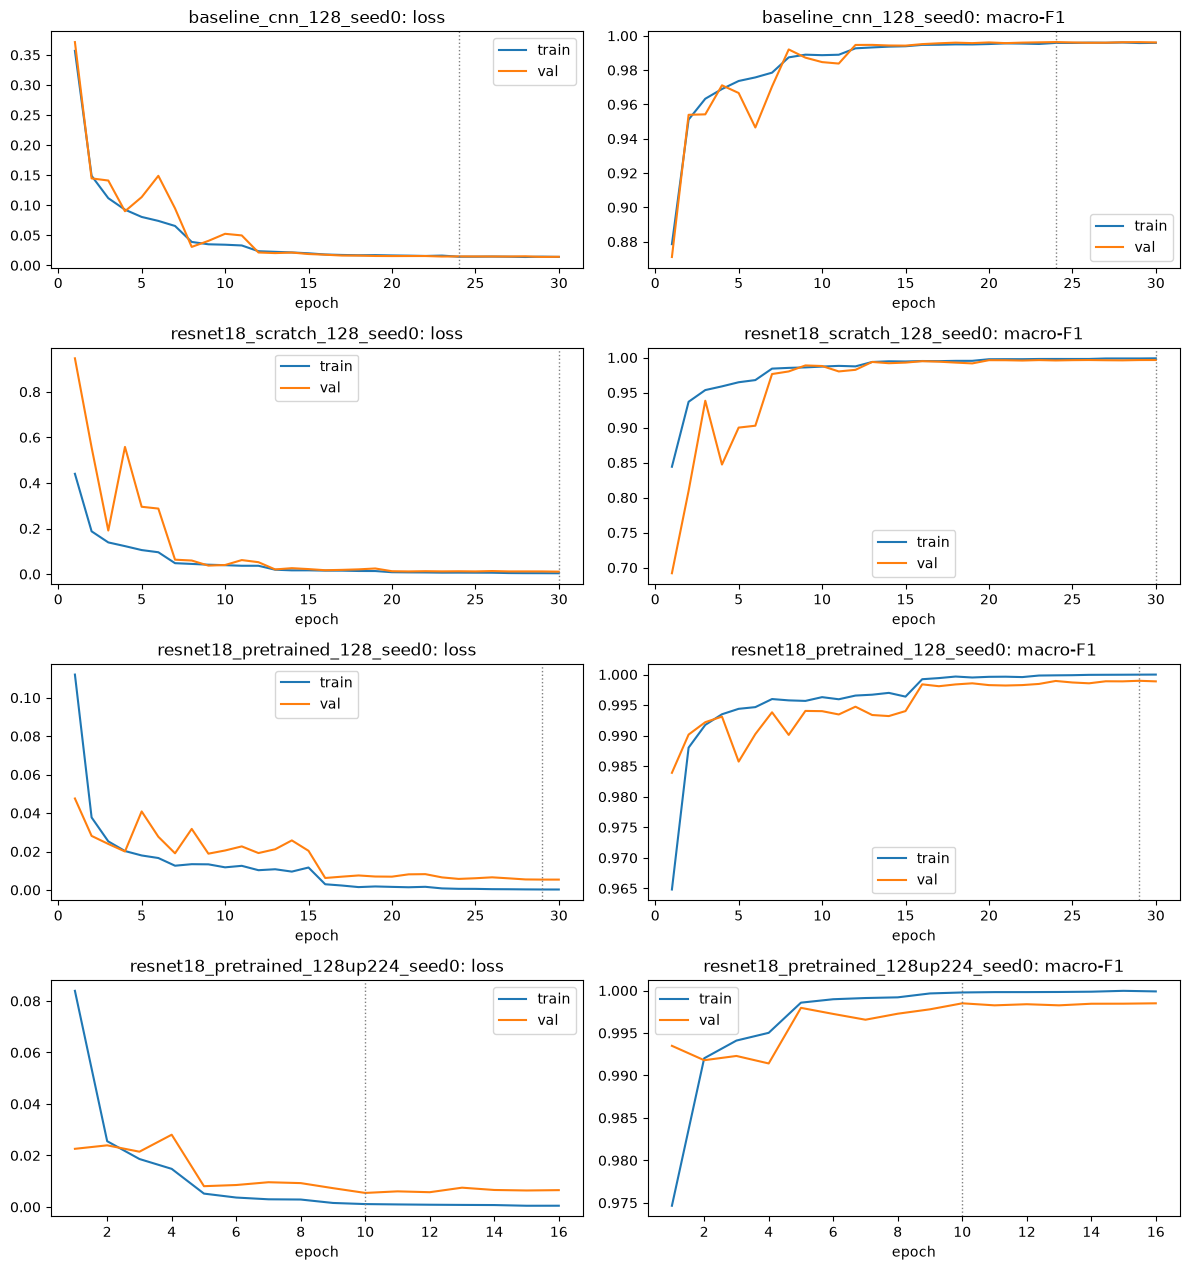

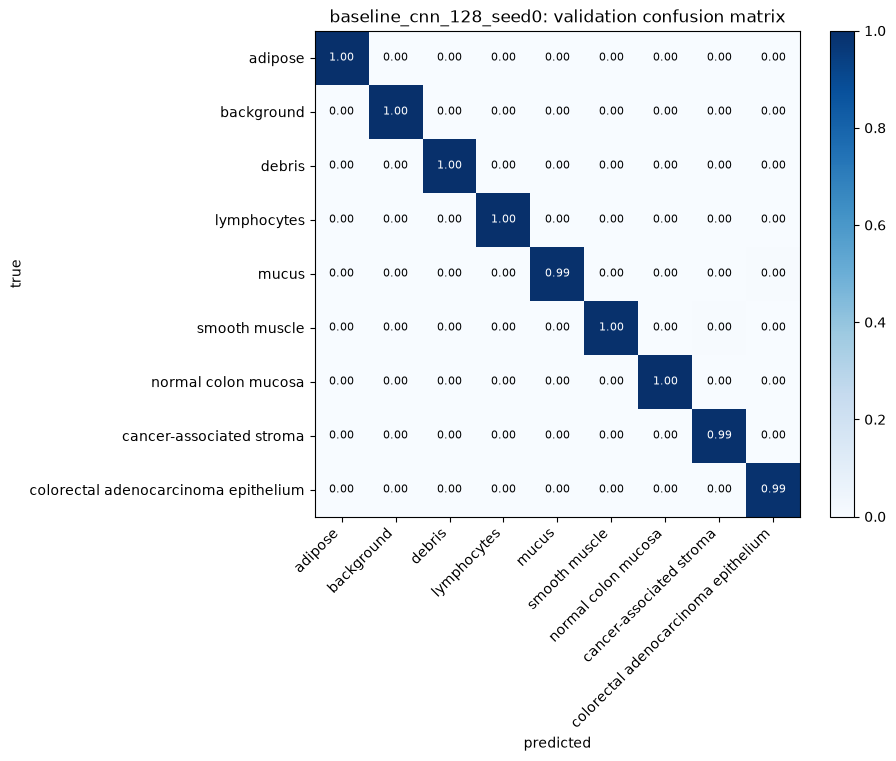

baseline_cnn_128_seed0


,precision,recall,F1
adipose,0.999,0.999,0.999
background,1.000,1.000,1.000
debris,0.997,0.997,0.997
lymphocytes,1.000,0.999,1.000
mucus,0.994,0.993,0.994
smooth muscle,0.996,0.996,0.996
normal colon mucosa,0.994,0.999,0.997
cancer-associated stroma,0.990,0.994,0.992
colorectal adenocarcinoma epithelium,0.996,0.992,0.994


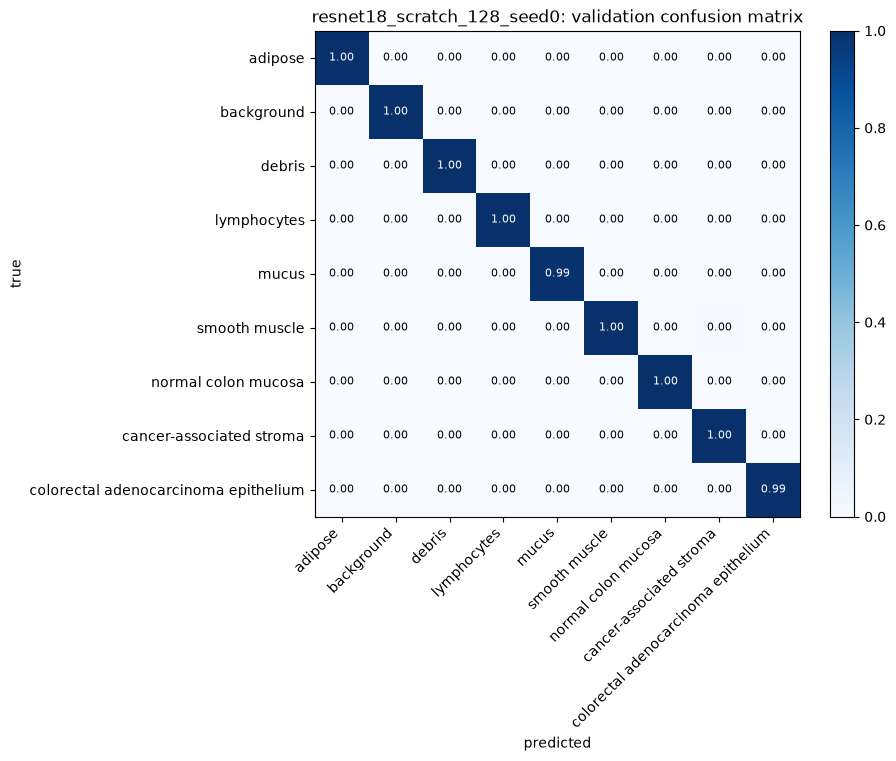

resnet18_scratch_128_seed0


,precision,recall,F1
adipose,0.999,1.000,1.000
background,1.000,1.000,1.000
debris,0.998,0.997,0.998
lymphocytes,0.998,1.000,0.999
mucus,0.994,0.991,0.993
smooth muscle,0.999,0.996,0.997
normal colon mucosa,0.993,0.997,0.995
cancer-associated stroma,0.990,0.995,0.992
colorectal adenocarcinoma epithelium,0.997,0.994,0.996


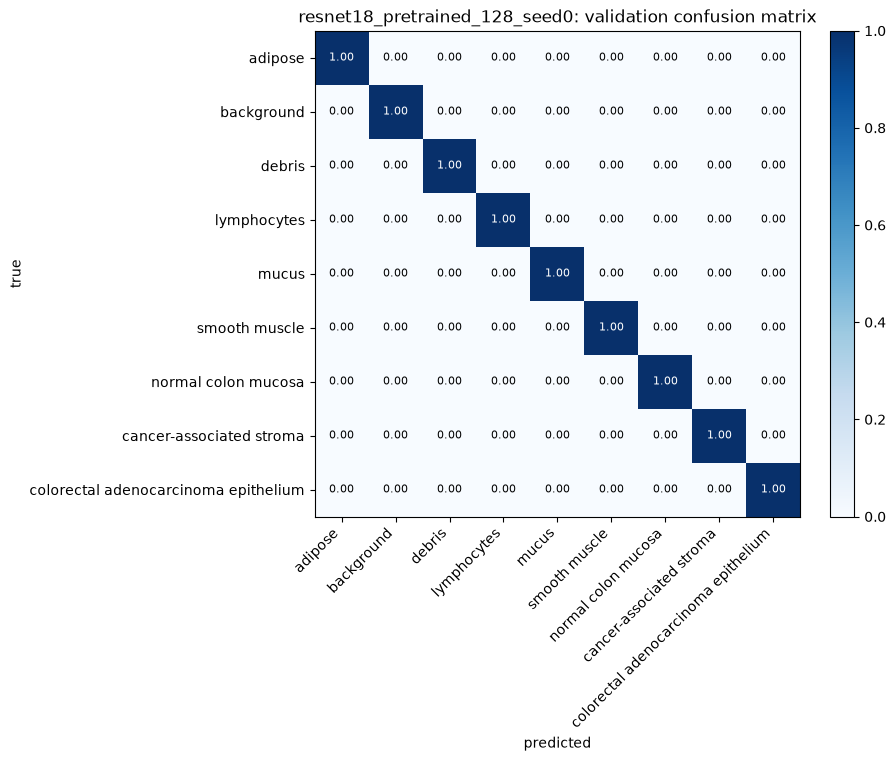

resnet18_pretrained_128_seed0


,precision,recall,F1
adipose,1.000,1.000,1.000
background,1.000,1.000,1.000
debris,1.000,0.998,0.999
lymphocytes,1.000,1.000,1.000
mucus,0.994,0.998,0.996
smooth muscle,1.000,1.000,1.000
normal colon mucosa,0.999,1.000,0.999
cancer-associated stroma,0.999,0.998,0.999
colorectal adenocarcinoma epithelium,0.998,0.997,0.998


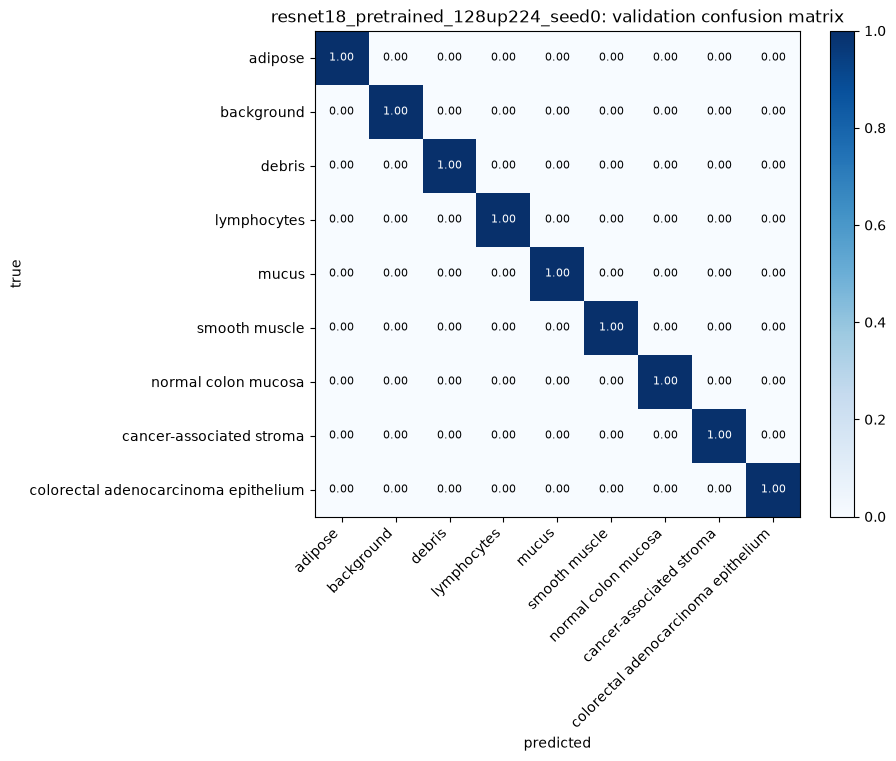

resnet18_pretrained_128up224_seed0


,precision,recall,F1
adipose,1.000,1.000,1.000
background,1.000,1.000,1.000
debris,1.000,0.997,0.999
lymphocytes,1.000,1.000,1.000
mucus,0.996,0.998,0.997
smooth muscle,0.997,1.000,0.999
normal colon mucosa,0.997,1.000,0.998
cancer-associated stroma,0.999,0.995,0.997
colorectal adenocarcinoma epithelium,0.998,0.997,0.997


In [2]:
import matplotlib.pyplot as plt
from src.report import (
    results_table, plot_history, plot_confusion, per_class_table,
)

RUN_NAMES = [
    "baseline_cnn_128_seed0",
    "resnet18_scratch_128_seed0",
    "resnet18_pretrained_128_seed0",
    "resnet18_pretrained_128up224_seed0",
]

runs = load_results(
    RUN_NAMES,
    results_dir=str(RESULTS),
)

display(results_table(runs))

plot_history(runs)
plt.show()

for run in runs:
    plot_confusion(run)
    plt.show()

    print(run["name"])
    display(per_class_table(run))